EAS 587 - Data Intensive Computing
Phase 2: GDELT Data Profiling and Exploratory analysis

Dataset: GDELT 1.0 Events, January 1st - June 13th 2025
Team: Data Wizards

Installing the required Python Libraries

In [5]:
%pip install pandas numpy matplotlib seaborn pyarrow scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Import libraries

In [6]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import scipy

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("PyArrow:", pa.__version__)
print("SciPy:", scipy.__version__)

print("\nEnvironment ready!")

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Pandas: 3.0.6
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
PyArrow: 26.0.0
SciPy: 1.18.1

Environment ready!


Dataset location

In [7]:
from pathlib import Path

# USER INPUT: Enter the path to your GDELT CSV file

FILE_PATH = r"C:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_2025_H1.csv"

# Dataset validation

DATA_PATH = Path(FILE_PATH).expanduser()

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Please check the file path above."
    )

print("Dataset:", DATA_PATH.name)
print("Location:", DATA_PATH.resolve())
print("File size (GB):", round(DATA_PATH.stat().st_size / 1e9, 2))

Dataset: gdelt_2025_H1.csv
Location: C:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\gdelt_2025_H1.csv
File size (GB): 8.05


Inspecting dataset structure

In [8]:
# Load a sample of 1,000 rows
df_sample = pd.read_csv(
    DATA_PATH,
    nrows=1000,
    dtype="string"
)

# Display dataset dimensions
print("Sample shape:", df_sample.shape)
print("Number of columns:", len(df_sample.columns))

# Display first 5 rows
display(df_sample.head())

# Display column names
print("\nColumn names:")
print(df_sample.columns.tolist())

Sample shape: (1000, 58)
Number of columns: 58


,GLOBALEVENTID,SQLDATE,MonthYear,Year,FractionDate,Actor1Code,Actor1Name,Actor1CountryCode,Actor1KnownGroupCode,Actor1EthnicCode,...,Actor2Geo_FeatureID,ActionGeo_Type,ActionGeo_FullName,ActionGeo_CountryCode,ActionGeo_ADM1Code,ActionGeo_Lat,ActionGeo_Long,ActionGeo_FeatureID,DATEADDED,SOURCEURL
0,1218366341,20240102,202401,2024,2024.0055,<NA>,<NA>,<NA>,<NA>,<NA>,...,CA,2,"Maryland, United States",US,USMD,39.0724,-76.7902,MD,20250101,https://www.scotusblog.com/2024/12/in-year-end...
1,1218366342,20240102,202401,2024,2024.0055,<NA>,<NA>,<NA>,<NA>,<NA>,...,MD,2,"Maryland, United States",US,USMD,39.0724,-76.7902,MD,20250101,https://www.scotusblog.com/2024/12/in-year-end...
2,1218366343,20240102,202401,2024,2024.0055,CAN,CANADA,CAN,<NA>,<NA>,...,<NA>,1,Canada,CA,CA,60,-96,CA,20250101,https://www.castanetkamloops.net/news/BC/52531...
3,1218366344,20240102,202401,2024,2024.0055,USA,UNITED STATES,USA,<NA>,<NA>,...,1474779,3,"Smithfield, Virginia, United States",US,USVA,36.9824,-76.6311,1474779,20250101,https://www.nbcbayarea.com/news/national-inter...
4,1218366345,20240102,202401,2024,2024.0055,USA,ATLANTA,USA,<NA>,<NA>,...,351615,3,"Atlanta, Georgia, United States",US,USGA,33.749,-84.388,351615,20250101,https://www.fbherald.com/news/state/jimmy-and-...



Column names:
['GLOBALEVENTID', 'SQLDATE', 'MonthYear', 'Year', 'FractionDate', 'Actor1Code', 'Actor1Name', 'Actor1CountryCode', 'Actor1KnownGroupCode', 'Actor1EthnicCode', 'Actor1Religion1Code', 'Actor1Religion2Code', 'Actor1Type1Code', 'Actor1Type2Code', 'Actor1Type3Code', 'Actor2Code', 'Actor2Name', 'Actor2CountryCode', 'Actor2KnownGroupCode', 'Actor2EthnicCode', 'Actor2Religion1Code', 'Actor2Religion2Code', 'Actor2Type1Code', 'Actor2Type2Code', 'Actor2Type3Code', 'IsRootEvent', 'EventCode', 'EventBaseCode', 'EventRootCode', 'QuadClass', 'GoldsteinScale', 'NumMentions', 'NumSources', 'NumArticles', 'AvgTone', 'Actor1Geo_Type', 'Actor1Geo_FullName', 'Actor1Geo_CountryCode', 'Actor1Geo_ADM1Code', 'Actor1Geo_Lat', 'Actor1Geo_Long', 'Actor1Geo_FeatureID', 'Actor2Geo_Type', 'Actor2Geo_FullName', 'Actor2Geo_CountryCode', 'Actor2Geo_ADM1Code', 'Actor2Geo_Lat', 'Actor2Geo_Long', 'Actor2Geo_FeatureID', 'ActionGeo_Type', 'ActionGeo_FullName', 'ActionGeo_CountryCode', 'ActionGeo_ADM1Code', 'A

Inspecting column data types and missing values 

In [9]:
# Create a profile of all 58 columns
column_profile = pd.DataFrame({
    "Column": df_sample.columns,
    "Data_Type": df_sample.dtypes.astype(str).values,
    "Unique_Values": df_sample.nunique().values,
    "Missing_Count": df_sample.isna().sum().values,
    "Missing_Percentage": (
        df_sample.isna().mean().values * 100
    ).round(2)
})

display(column_profile)

,Column,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
0,GLOBALEVENTID,string,1000,0,0.0
1,SQLDATE,string,4,0,0.0
2,MonthYear,string,3,0,0.0
3,Year,string,2,0,0.0
4,FractionDate,string,4,0,0.0
5,Actor1Code,string,95,224,22.4
6,Actor1Name,string,207,224,22.4
7,Actor1CountryCode,string,43,710,71.0
8,Actor1KnownGroupCode,string,5,992,99.2
9,Actor1EthnicCode,string,0,1000,100.0


Using Chunked Pandas (chunk size = 100,000) to calculate actual missing values across all 58 columns. This is to see which columns we can omit based on sparcity.

In [10]:
# Initialize missing-value counters
missing_counts = pd.Series(
    0,
    index=df_sample.columns,
    dtype="int64"
)

total_rows = 0
CHUNK_SIZE = 100_000

# Read the complete dataset in chunks
for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        dtype="string",
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    total_rows += len(chunk)
    missing_counts += chunk.isna().sum()

    if i % 20 == 0:
        print(f"Processed {total_rows:,} rows")

# Create missing-value profile
missing_profile = pd.DataFrame({
    "Column": missing_counts.index,
    "Missing_Count": missing_counts.values,
    "Missing_Percentage": (
        missing_counts.values / total_rows * 100
    ).round(2)
})

missing_profile = missing_profile.sort_values(
    "Missing_Percentage",
    ascending=False
)

print(f"\nTotal records processed: {total_rows:,}")
display(missing_profile)

Processed 2,000,000 rows
Processed 4,000,000 rows
Processed 6,000,000 rows
Processed 8,000,000 rows
Processed 10,000,000 rows
Processed 12,000,000 rows
Processed 14,000,000 rows
Processed 16,000,000 rows
Processed 18,000,000 rows
Processed 20,000,000 rows

Total records processed: 20,343,168


,Column,Missing_Count,Missing_Percentage
24,Actor2Type3Code,20335010,99.96
14,Actor1Type3Code,20330937,99.94
21,Actor2Religion2Code,20281119,99.69
11,Actor1Religion2Code,20266660,99.62
19,Actor2EthnicCode,20243269,99.51
9,Actor1EthnicCode,20216678,99.38
18,Actor2KnownGroupCode,20155580,99.08
20,Actor2Religion1Code,20125217,98.93
8,Actor1KnownGroupCode,20116663,98.89
10,Actor1Religion1Code,20085570,98.73


Cleaning note: Should remove the columns that are above 90% missing along with the columns that Might not be relevant to crude oil prices (Decision to be documented)

SQLDATE which is the date the article was published has 2024 dates which is possible and it could be used to determine Jan 1st 2025 Crude oil prices too. 

In [11]:
# Count events for every SQLDATE across all chunks
date_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["SQLDATE"],
    dtype={"SQLDATE": "string"},
    chunksize=100_000
):
    counts = chunk["SQLDATE"].value_counts()

    date_counts = date_counts.add(
        counts,
        fill_value=0
    )

date_counts = date_counts.fillna(0).astype("int64")
date_counts = date_counts.sort_index()

# Convert GDELT date strings to actual dates
dates = pd.to_datetime(
    date_counts.index,
    format="%Y%m%d",
    errors="coerce"
)

print("Earliest SQLDATE:", dates.min())
print("Latest SQLDATE:", dates.max())
print("Unique event dates:", len(date_counts))
print("Invalid dates:", dates.isna().sum())

# Count records by year
year_counts = pd.DataFrame({
    "Year": dates.year,
    "Count": date_counts.values
}).groupby("Year")["Count"].sum()

display(year_counts)

# Save results
date_counts.to_csv(
    "gdelt_daily_counts.csv",
    header=["Event_Count"]
)

Earliest SQLDATE: 2015-01-04 00:00:00
Latest SQLDATE: 2025-06-13 00:00:00
Unique event dates: 522
Invalid dates: 0


Year
2015        4324
2024      188062
2025    20150782
Name: Count, dtype: int64

Cleaning note: We should remove all the 2015 columns and possibly some of the older 2024 columns.

Checking the DATEADDED field

In [12]:
# Count DATEADDED values across the entire dataset
added_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["DATEADDED"],
    dtype={"DATEADDED": "string"},
    chunksize=100_000
):
    counts = chunk["DATEADDED"].str[:8].value_counts()

    added_counts = added_counts.add(counts, fill_value=0)

added_counts = added_counts.fillna(0).astype("int64").sort_index()

print("Earliest DATEADDED:", added_counts.index.min())
print("Latest DATEADDED:", added_counts.index.max())
print("Unique DATEADDED dates:", len(added_counts))

display(added_counts.head(10))
display(added_counts.tail(10))

Earliest DATEADDED: 20250101
Latest DATEADDED: 20250613
Unique DATEADDED dates: 164


DATEADDED
20250101     71207
20250102     91632
20250103    106495
20250104     74608
20250105     64742
20250106    110445
20250107    129240
20250108    136893
20250109    140097
20250110    129292
dtype: int64

DATEADDED
20250604    141508
20250605    143602
20250606    130876
20250607     80526
20250608     69520
20250609    118686
20250610    140233
20250611    148335
20250612    136620
20250613    151538
dtype: int64

Check duplicate GLOBALEVENTID

In [26]:
import pandas as pd
import sqlite3
from pathlib import Path

# Temporary SQLite database for checking duplicates
DB_PATH = Path("gdelt_duplicate_check.db")

# Connect to database
conn = sqlite3.connect(DB_PATH)

conn.execute("""
    CREATE TABLE IF NOT EXISTS event_ids (
        GLOBALEVENTID TEXT PRIMARY KEY
    )
""")

total_rows = 0
duplicate_count = 0
CHUNK_SIZE = 100_000

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=["GLOBALEVENTID"],
        dtype={"GLOBALEVENTID": "string"},
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    ids = [(str(x),) for x in chunk["GLOBALEVENTID"]]

    before = conn.total_changes

    conn.executemany(
        "INSERT OR IGNORE INTO event_ids VALUES (?)",
        ids
    )

    inserted = conn.total_changes - before
    duplicate_count += len(ids) - inserted
    total_rows += len(ids)

    if i % 20 == 0:
        conn.commit()
        print(f"Processed {total_rows:,} rows")

conn.commit()

unique_count = conn.execute(
    "SELECT COUNT(*) FROM event_ids"
).fetchone()[0]

conn.close()

print("\n--- Duplicate ID Report ---")
print(f"Total records: {total_rows:,}")
print(f"Unique event IDs: {unique_count:,}")
print(f"Duplicate IDs: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_count / total_rows * 100:.4f}%")

Processed 2,000,000 rows
Processed 4,000,000 rows
Processed 6,000,000 rows
Processed 8,000,000 rows
Processed 10,000,000 rows
Processed 12,000,000 rows
Processed 14,000,000 rows
Processed 16,000,000 rows
Processed 18,000,000 rows
Processed 20,000,000 rows

--- Duplicate ID Report ---
Total records: 20,343,168
Unique event IDs: 20,343,168
Duplicate IDs: 0
Duplicate percentage: 0.0000%


how many distinct event codes, countries, and classification values occur in the complete dataset.

In [27]:
# Columns to analyze
categorical_cols = [
    "EventRootCode",
    "EventBaseCode",
    "EventCode",
    "QuadClass",
    "Actor1CountryCode",
    "Actor2CountryCode",
    "ActionGeo_CountryCode",
    "IsRootEvent"
]

# Store unique values for each column
unique_values = {
    col: set() for col in categorical_cols
}

CHUNK_SIZE = 100_000

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=categorical_cols,
        dtype="string",
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    for col in categorical_cols:
        unique_values[col].update(
            chunk[col].dropna().unique()
        )

    if i % 20 == 0:
        print(f"Processed {i * CHUNK_SIZE:,} rows")

# Generate cardinality report
cardinality_profile = pd.DataFrame({
    "Column": categorical_cols,
    "Unique_Values": [
        len(unique_values[col])
        for col in categorical_cols
    ]
})

display(cardinality_profile)

Processed 2,000,000 rows
Processed 4,000,000 rows
Processed 6,000,000 rows
Processed 8,000,000 rows
Processed 10,000,000 rows
Processed 12,000,000 rows
Processed 14,000,000 rows
Processed 16,000,000 rows
Processed 18,000,000 rows
Processed 20,000,000 rows


,Column,Unique_Values
0,EventRootCode,22
1,EventBaseCode,144
2,EventCode,254
3,QuadClass,4
4,Actor1CountryCode,219
5,Actor2CountryCode,218
6,ActionGeo_CountryCode,256
7,IsRootEvent,2


EventRootCode frequency and CAMEO descriptions

In [15]:
# Official CAMEO root event descriptions
cameo_root = {
    "01": "Make Public Statement",
    "02": "Appeal",
    "03": "Express Intent to Cooperate",
    "04": "Consult",
    "05": "Engage in Diplomatic Cooperation",
    "06": "Engage in Material Cooperation",
    "07": "Provide Aid",
    "08": "Yield",
    "09": "Investigate",
    "10": "Demand",
    "11": "Disapprove",
    "12": "Reject",
    "13": "Threaten",
    "14": "Protest",
    "15": "Exhibit Force Posture",
    "16": "Reduce Relations",
    "17": "Coerce",
    "18": "Assault",
    "19": "Fight",
    "20": "Engage in Unconventional Mass Violence"
}

# Count event root codes across the complete dataset
root_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["EventRootCode"],
    dtype="string",
    chunksize=100_000
):
    counts = chunk["EventRootCode"].value_counts(dropna=False)

    root_counts = root_counts.add(counts, fill_value=0)

# Create frequency table
root_profile = (
    root_counts.fillna(0)
    .astype("int64")
    .rename_axis("EventRootCode")
    .reset_index(name="Count")
)

# Add CAMEO descriptions
root_profile["Description"] = (
    root_profile["EventRootCode"]
    .map(cameo_root)
    .fillna("Unknown / Non-standard code")
)

root_profile["Percentage"] = (
    root_profile["Count"] / root_profile["Count"].sum() * 100
).round(2)

# Sort in descending order
root_profile = root_profile.sort_values(
    "Count", ascending=False
)

display(root_profile)

,EventRootCode,Count,Description,Percentage
4,04,5103696,Consult,25.09
1,01,2856569,Make Public Statement,14.04
5,05,1799597,Engage in Diplomatic Cooperation,8.85
2,02,1450320,Appeal,7.13
3,03,1359217,Express Intent to Cooperate,6.68
11,11,1294549,Disapprove,6.36
19,19,1171487,Fight,5.76
17,17,1031142,Coerce,5.07
8,08,746460,Yield,3.67
7,07,729467,Provide Aid,3.59


EventRootCode frequency bar chart

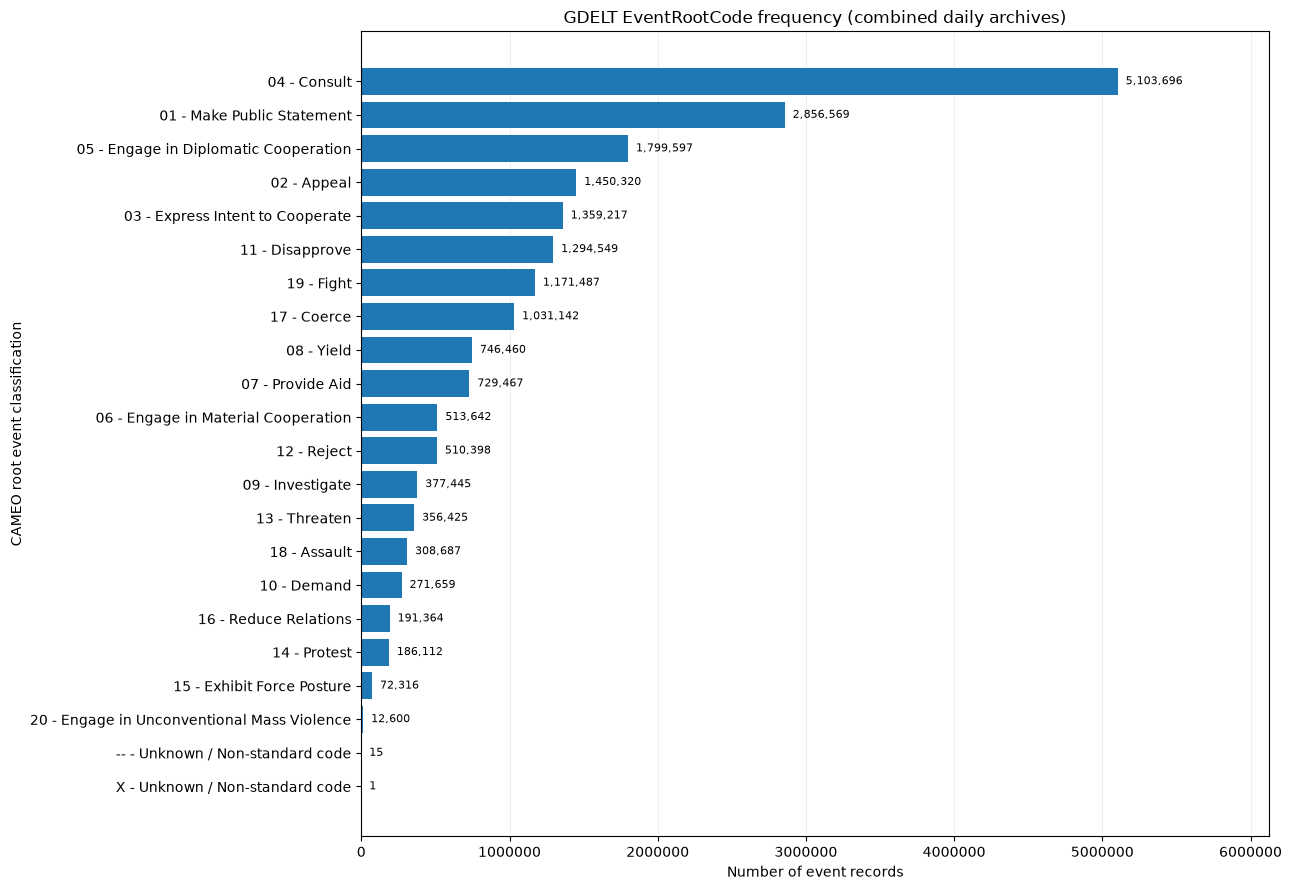

In [16]:
# Uses root_profile from the preceding cell; avoids reading the 8 GB CSV again.
plot_data = root_profile.copy().sort_values("Count", ascending=True)
plot_labels = plot_data["EventRootCode"].astype(str) + " - " + plot_data["Description"]

fig, ax = plt.subplots(figsize=(13, 9))
ax.barh(plot_labels, plot_data["Count"])
ax.set_title("GDELT EventRootCode frequency (combined daily archives)")
ax.set_xlabel("Number of event records")
ax.set_ylabel("CAMEO root event classification")
ax.ticklabel_format(axis="x", style="plain")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.set_xlim(0, plot_data["Count"].max() * 1.20)
for i, count in enumerate(plot_data["Count"]):
    ax.text(count, i, f"  {count:,}", va="center", fontsize=8)
fig.tight_layout()
plt.show()

# Save summaries and figure alongside the input file; these small files can be reused.
PROFILE_DIR = DATA_PATH.parent / "profile_results"
PROFILE_DIR.mkdir(exist_ok=True)
root_profile.to_csv(PROFILE_DIR / "eventrootcode_counts.csv", index=False)
fig.savefig(PROFILE_DIR / "eventrootcode_frequency.png", dpi=180, bbox_inches="tight")

Inspecting unexpected EventRootCode values

In [17]:
# Standard CAMEO root classifications are 01–20.
# Values outside that list need inspection, not automatic deletion.
root_profile["EventRootCode"] = root_profile["EventRootCode"].astype("string")
unexpected_root = root_profile.loc[
    ~root_profile["EventRootCode"].isin(list(cameo_root))
].sort_values("Count", ascending=False)
print("Unexpected root-code values:")
display(unexpected_root)
unexpected_root.to_csv(PROFILE_DIR / "unexpected_eventrootcodes.csv", index=False)

Unexpected root-code values:


,EventRootCode,Count,Description,Percentage
0,--,15,Unknown / Non-standard code,0.0
21,X,1,Unknown / Non-standard code,0.0


DATEADDED daily record counts and coverage

Archive date range: 2025-01-01 00:00:00 to 2025-06-13 00:00:00
Days represented: 164 | Missing dates in range: 0
Daily events — minimum: 64742 | median: 136635.0 | maximum: 161604
Missing archive dates: []


,ArchiveDate,EventCount
4,2025-01-05,64742
102,2025-04-13,68647
158,2025-06-08,69520
0,2025-01-01,71207
151,2025-06-01,71507
11,2025-01-12,71591
144,2025-05-25,72245
123,2025-05-04,72615
39,2025-02-09,72628
95,2025-04-06,74066


,ArchiveDate,EventCount
112,2025-04-23,161604
126,2025-05-07,161183
113,2025-04-24,158308
35,2025-02-05,157391
70,2025-03-12,155839
63,2025-03-05,154805
127,2025-05-08,154460
134,2025-05-15,154382
71,2025-03-13,153903
133,2025-05-14,153680


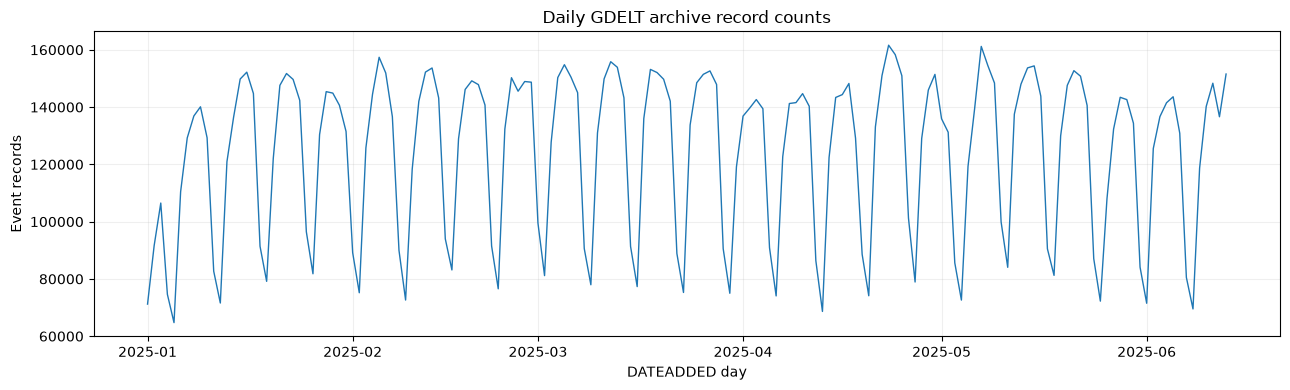

In [18]:
# DATEADDED is YYYYMMDDHHMMSS; use the first 8 characters for archive-day profiling.
# added_counts comes from the earlier DATEADDED profiling cell.
archive_daily = added_counts.rename_axis("ArchiveDate").reset_index(name="EventCount")
archive_daily["ArchiveDate"] = pd.to_datetime(archive_daily["ArchiveDate"], format="%Y%m%d", errors="coerce")
archive_daily = archive_daily.sort_values("ArchiveDate")
expected_days = pd.date_range(archive_daily["ArchiveDate"].min(), archive_daily["ArchiveDate"].max(), freq="D")
missing_days = expected_days.difference(pd.DatetimeIndex(archive_daily["ArchiveDate"].dropna()))
print("Archive date range:", archive_daily["ArchiveDate"].min(), "to", archive_daily["ArchiveDate"].max())
print("Days represented:", len(archive_daily), "| Missing dates in range:", len(missing_days))
print("Daily events — minimum:", archive_daily["EventCount"].min(),
      "| median:", archive_daily["EventCount"].median(),
      "| maximum:", archive_daily["EventCount"].max())
print("Missing archive dates:", [x.strftime("%Y-%m-%d") for x in missing_days])
display(archive_daily.nsmallest(10, "EventCount"))
display(archive_daily.nlargest(10, "EventCount"))
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(archive_daily["ArchiveDate"], archive_daily["EventCount"], linewidth=1)
ax.set(title="Daily GDELT archive record counts", xlabel="DATEADDED day", ylabel="Event records")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
archive_daily.to_csv(PROFILE_DIR / "daily_dateadded_counts.csv", index=False)
fig.savefig(PROFILE_DIR / "daily_dateadded_counts.png", dpi=180, bbox_inches="tight")

SQLDATE and DATEADDED differences

In [19]:
# This is an important temporal-quality check for oil-price forecasting.
# SQLDATE is the date attributed to the event; DATEADDED indicates when GDELT added the record.
# Do not assume SQLDATE is the news article publication date.
lag_bins = {"event_after_added": 0, "same_day": 0, "1_to_7_days_old": 0,
            "8_to_30_days_old": 0, "31_to_365_days_old": 0, "more_than_365_days_old": 0,
            "invalid_dates": 0}
examples_old = []
for chunk in pd.read_csv(DATA_PATH,
                         usecols=["GLOBALEVENTID", "SQLDATE", "DATEADDED"],
                         dtype="string", chunksize=CHUNK_SIZE):
    event_date = pd.to_datetime(chunk["SQLDATE"], format="%Y%m%d", errors="coerce")
    added_date = pd.to_datetime(chunk["DATEADDED"].str[:8], format="%Y%m%d", errors="coerce")
    lag = (added_date - event_date).dt.days
    lag_bins["invalid_dates"] += int(lag.isna().sum())
    lag_bins["event_after_added"] += int((lag < 0).sum())
    lag_bins["same_day"] += int((lag == 0).sum())
    lag_bins["1_to_7_days_old"] += int(lag.between(1, 7).sum())
    lag_bins["8_to_30_days_old"] += int(lag.between(8, 30).sum())
    lag_bins["31_to_365_days_old"] += int(lag.between(31, 365).sum())
    lag_bins["more_than_365_days_old"] += int((lag > 365).sum())
    if len(examples_old) < 15:
        older = chunk.loc[(lag > 365), ["GLOBALEVENTID", "SQLDATE", "DATEADDED"]]
        examples_old.extend(older.head(15 - len(examples_old)).to_dict("records"))
lag_profile = pd.DataFrame(lag_bins.items(), columns=["DateRelationship", "Count"])
lag_profile["Percentage"] = (100 * lag_profile["Count"] / lag_profile["Count"].sum()).round(4)
display(lag_profile)
print("Examples of records more than a year old:")
display(pd.DataFrame(examples_old))
lag_profile.to_csv(PROFILE_DIR / "sqldate_dateadded_lags.csv", index=False)

,DateRelationship,Count,Percentage
0,event_after_added,0,0.0000
1,same_day,19838867,97.5210
2,1_to_7_days_old,225445,1.1082
3,8_to_30_days_old,104968,0.5160
4,31_to_365_days_old,169564,0.8335
5,more_than_365_days_old,4324,0.0213
6,invalid_dates,0,0.0000


Examples of records more than a year old:


,GLOBALEVENTID,SQLDATE,DATEADDED
0,1218375626,20150104,20250101
1,1218375627,20150104,20250101
2,1218375628,20150104,20250101
3,1218383085,20150104,20250101
4,1218383086,20150104,20250101
5,1218390113,20150104,20250101
6,1218390114,20150104,20250101
7,1218390115,20150104,20250101
8,1218390116,20150104,20250101
9,1218390117,20150104,20250101


Numerical data type and range validation

In [20]:
# Analyze all records using only numeric fields (lower memory than reading 58 columns).
# Domain limits here are initial sanity checks; they do not determine cleaning automatically.
numeric_fields = ["GoldsteinScale", "NumMentions", "NumSources", "NumArticles", "AvgTone",
                  "Actor1Geo_Lat", "Actor1Geo_Long", "Actor2Geo_Lat", "Actor2Geo_Long",
                  "ActionGeo_Lat", "ActionGeo_Long"]
stats = {col: {"nonmissing": 0, "invalid_numeric": 0, "min": float("inf"),
               "max": float("-inf"), "negative": 0, "zero": 0, "out_of_range": 0}
         for col in numeric_fields}
for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=numeric_fields,
                                      dtype="string", chunksize=CHUNK_SIZE), start=1):
    for col in numeric_fields:
        raw = chunk[col]
        values = pd.to_numeric(raw, errors="coerce")
        valid = values.dropna()
        st = stats[col]
        st["nonmissing"] += int(raw.notna().sum())
        st["invalid_numeric"] += int((raw.notna() & values.isna()).sum())
        if len(valid):
            st["min"] = min(st["min"], float(valid.min()))
            st["max"] = max(st["max"], float(valid.max()))
            st["negative"] += int((valid < 0).sum())
            st["zero"] += int((valid == 0).sum())
            if col.endswith("_Lat"):
                st["out_of_range"] += int(((valid < -90) | (valid > 90)).sum())
            elif col.endswith("_Long"):
                st["out_of_range"] += int(((valid < -180) | (valid > 180)).sum())
            elif col in ["NumMentions", "NumSources", "NumArticles"]:
                st["out_of_range"] += int((valid < 0).sum())
            elif col in ["AvgTone", "GoldsteinScale"]:
                st["out_of_range"] += int(((valid < -100) | (valid > 100)).sum())
    if i % 40 == 0:
        print(f"Processed {i * CHUNK_SIZE:,} rows")
numeric_profile = pd.DataFrame.from_dict(stats, orient="index").rename_axis("Column").reset_index()
numeric_profile[["min", "max"]] = numeric_profile[["min", "max"]].replace({float("inf"): np.nan, float("-inf"): np.nan})
display(numeric_profile)
numeric_profile.to_csv(PROFILE_DIR / "numeric_validation.csv", index=False)

Processed 4,000,000 rows
Processed 8,000,000 rows
Processed 12,000,000 rows
Processed 16,000,000 rows
Processed 20,000,000 rows


,Column,nonmissing,invalid_numeric,min,max,negative,zero,out_of_range
0,GoldsteinScale,20343058,0,-10.000000,10.000000,6280416,2010699,0
1,NumMentions,20343168,0,1.000000,14810.000000,0,0,0
2,NumSources,20343168,0,1.000000,796.000000,0,0,0
3,NumArticles,20343168,0,1.000000,10423.000000,0,0,0
4,AvgTone,20343168,0,-41.935484,29.166667,13740715,350820,0
5,Actor1Geo_Lat,17962412,0,-85.622100,85.000000,1216113,2167,0
6,Actor1Geo_Long,17964872,0,-179.983000,180.000000,8580744,1126,0
7,Actor2Geo_Lat,14312296,0,-85.622100,85.000000,926713,1845,0
8,Actor2Geo_Long,14314165,0,-179.983000,180.000000,6529055,835,0
9,ActionGeo_Lat,19800196,0,-85.622100,85.000000,1350696,2302,0


Categorical values and CAMEO event code frequencies

In [21]:
# Count specific categories over ALL records, and preserve leading zeros.
# Root codes have already been counted; here we inspect EventCode, QuadClass and flags.
from collections import Counter
cat_cols = ["EventCode", "EventBaseCode", "QuadClass", "IsRootEvent", "ActionGeo_CountryCode"]
counters = {col: Counter() for col in cat_cols}
for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=cat_cols,
                                      dtype="string", chunksize=CHUNK_SIZE), start=1):
    for col in cat_cols:
        counters[col].update(chunk[col].dropna().astype(str).value_counts().to_dict())
    if i % 40 == 0:
        print(f"Processed {i * CHUNK_SIZE:,} rows")
for col in cat_cols:
    table = pd.DataFrame(counters[col].most_common(), columns=[col, "Count"])
    table["PercentageOfAllRecords"] = (table["Count"] / total_rows * 100).round(3)
    table.to_csv(PROFILE_DIR / f"counts_{col}.csv", index=False)
    print(f"\n{col}: {len(table)} unique non-null codes")
    display(table.head(20))
print("Check unexpected QuadClass and IsRootEvent values:")
print("QuadClass:", sorted(counters["QuadClass"].keys()))
print("IsRootEvent:", sorted(counters["IsRootEvent"].keys()))

Processed 4,000,000 rows
Processed 8,000,000 rows
Processed 12,000,000 rows
Processed 16,000,000 rows
Processed 20,000,000 rows

EventCode: 254 unique non-null codes


,EventCode,Count,PercentageOfAllRecords
0,010,1609021,7.909
1,042,1582668,7.780
2,043,1479444,7.272
3,040,1281517,6.299
4,051,1269863,6.242
5,020,1207339,5.935
6,036,783524,3.852
7,190,771113,3.791
8,173,674817,3.317
9,046,662051,3.254



EventBaseCode: 144 unique non-null codes


,EventBaseCode,Count,PercentageOfAllRecords
0,010,1609021,7.909
1,042,1582668,7.780
2,043,1479444,7.272
3,040,1281517,6.299
4,051,1269863,6.242
5,020,1207339,5.935
6,036,783524,3.852
7,190,771113,3.791
8,173,674817,3.317
9,046,662051,3.254



QuadClass: 4 unique non-null codes


...


IsRootEvent: 2 unique non-null codes


,IsRootEvent,Count,PercentageOfAllRecords
0,1,11950221,58.743
1,0,8392947,41.257



ActionGeo_CountryCode: 256 unique non-null codes


,ActionGeo_CountryCode,Count,PercentageOfAllRecords
0,US,6589083,32.390
1,IN,1060992,5.215
2,UK,1023706,5.032
3,IS,899672,4.422
4,CA,594389,2.922
5,CH,578763,2.845
6,NI,545207,2.680
7,RS,536275,2.636
8,UP,519005,2.551
9,AS,434169,2.134


Check unexpected QuadClass and IsRootEvent values:
QuadClass: ['1', '2', '3', '4']
IsRootEvent: ['0', '1']


Geographic data coverage and country distributions

,Column,Missing_Count,Missing_Percentage
17,Actor2CountryCode,11013898,54.14
7,Actor1CountryCode,8717254,42.85
46,Actor2Geo_Lat,6030872,29.65
47,Actor2Geo_Long,6029003,29.64
44,Actor2Geo_CountryCode,6026909,29.63
39,Actor1Geo_Lat,2380756,11.70
40,Actor1Geo_Long,2378296,11.69
37,Actor1Geo_CountryCode,2375540,11.68
53,ActionGeo_Lat,542972,2.67
54,ActionGeo_Long,539864,2.65


,CountryCode,Count,ShareOfAllEventsPct
0,US,6589083,32.39
1,IN,1060992,5.22
2,UK,1023706,5.03
3,IS,899672,4.42
4,CA,594389,2.92
5,CH,578763,2.84
6,NI,545207,2.68
7,RS,536275,2.64
8,UP,519005,2.55
9,AS,434169,2.13


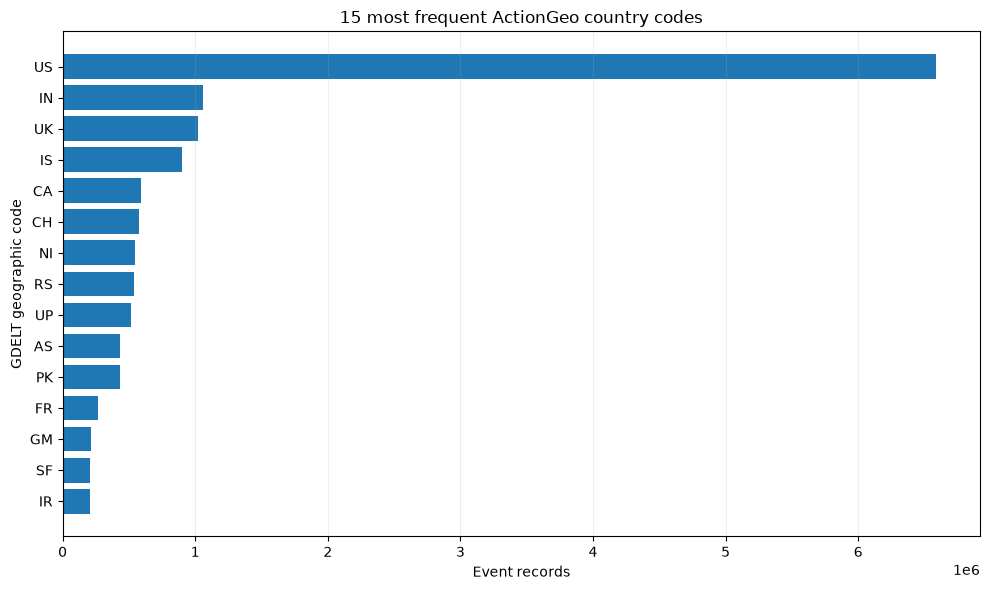

In [22]:
# Check completeness of location fields and coverage relevant to oil-exporter analyses.
# This uses missing_profile calculated earlier and the country frequency table above.
geo_cols = ["Actor1CountryCode", "Actor2CountryCode", "ActionGeo_CountryCode",
            "Actor1Geo_CountryCode", "Actor2Geo_CountryCode",
            "Actor1Geo_Lat", "Actor1Geo_Long", "Actor2Geo_Lat", "Actor2Geo_Long",
            "ActionGeo_Lat", "ActionGeo_Long"]
geo_missing = missing_profile.loc[missing_profile["Column"].isin(geo_cols)].copy()
display(geo_missing.sort_values("Missing_Percentage", ascending=False))
country_table = pd.DataFrame(counters["ActionGeo_CountryCode"].most_common(),
                             columns=["CountryCode", "Count"])
country_table["ShareOfAllEventsPct"] = (100 * country_table["Count"] / total_rows).round(2)
display(country_table.head(20))
fig, ax = plt.subplots(figsize=(10, 6))
top_countries = country_table.head(15).iloc[::-1]
ax.barh(top_countries["CountryCode"], top_countries["Count"])
ax.set(title="15 most frequent ActionGeo country codes", xlabel="Event records", ylabel="GDELT geographic code")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()
country_table.to_csv(PROFILE_DIR / "country_actiongeo_counts.csv", index=False)
fig.savefig(PROFILE_DIR / "top_actiongeo_countries.png", dpi=180, bbox_inches="tight")

Missingness and daily reporting visualizations

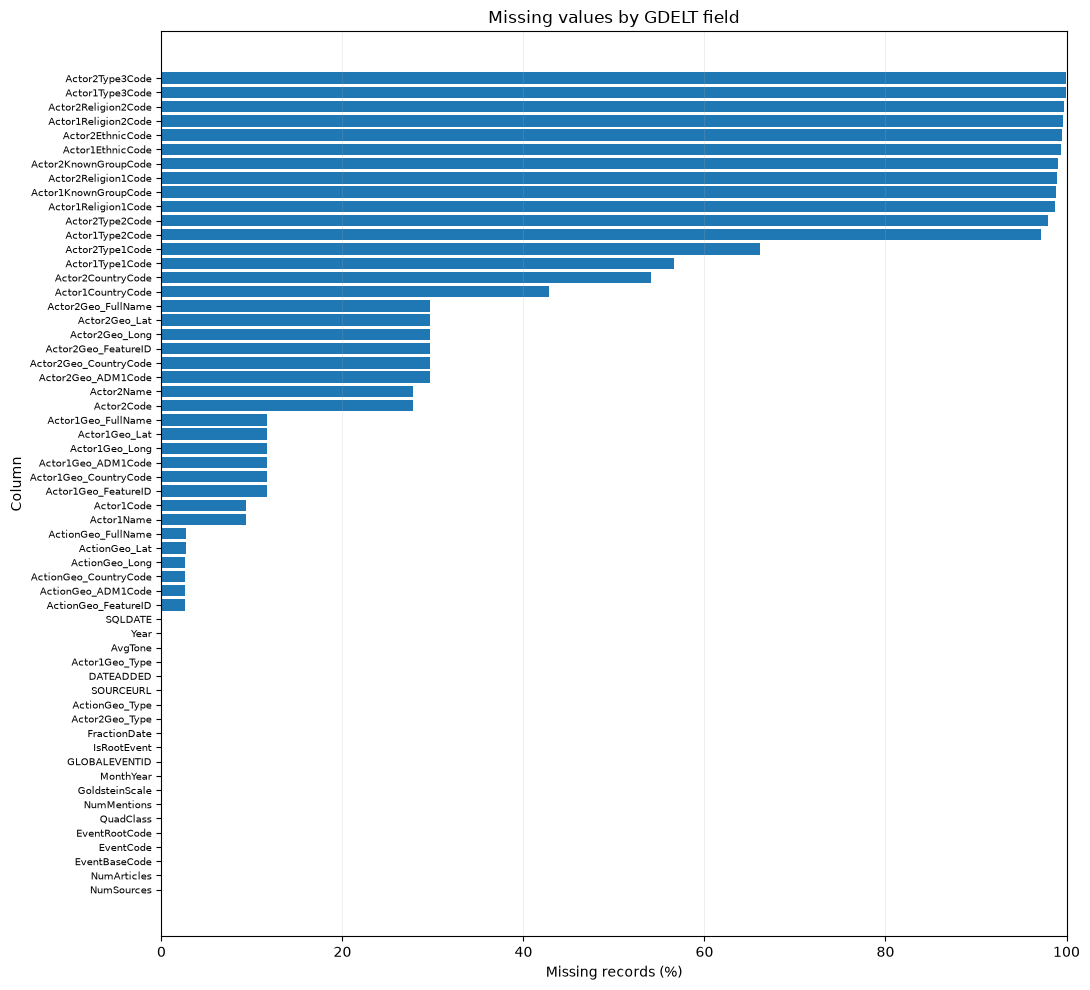

,count,median,mean
DayOfWeek,,,
Monday,23,125750.0,125340.826087
Tuesday,23,145389.0,143738.043478
Wednesday,24,150604.0,146348.000000
Thursday,24,149293.0,145644.875000
Friday,24,141388.5,139268.458333
Saturday,23,90503.0,89811.608696
Sunday,23,75174.0,75583.260870


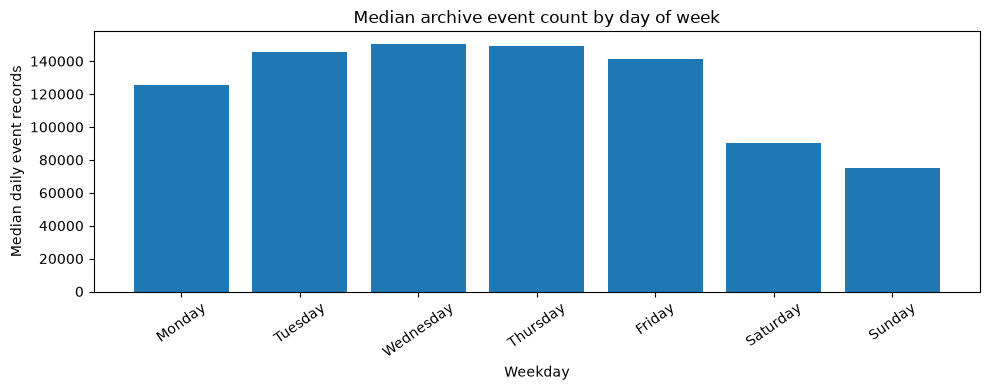

In [23]:
# Visualize the previous profiling results without rescanning the CSV.
fig, ax = plt.subplots(figsize=(11, 10))
missing_plot = missing_profile.sort_values("Missing_Percentage", ascending=True)
ax.barh(missing_plot["Column"], missing_plot["Missing_Percentage"])
ax.set(title="Missing values by GDELT field", xlabel="Missing records (%)", ylabel="Column")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.2)
ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
plt.show()
fig.savefig(PROFILE_DIR / "missingness_by_column.png", dpi=180, bbox_inches="tight")

# Comparison of weekdays and weekends in raw reporting (descriptive, not adjusted for holidays).
archive_daily["DayOfWeek"] = archive_daily["ArchiveDate"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_profile = archive_daily.groupby("DayOfWeek")["EventCount"].agg(["count", "median", "mean"])
weekday_profile = weekday_profile.reindex(weekday_order)
display(weekday_profile)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekday_profile.index, weekday_profile["median"])
ax.set(title="Median archive event count by day of week", xlabel="Weekday", ylabel="Median daily event records")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()
weekday_profile.to_csv(PROFILE_DIR / "weekday_event_counts.csv")
fig.savefig(PROFILE_DIR / "weekday_event_counts.png", dpi=180, bbox_inches="tight")

Profiling results and cleaning-stage checklist

In [24]:
# Profiling does not change the original CSV. Save a working list of issues to examine in cleaning.
cleaning_checks = [
    "Review fields with >90% missingness before deciding whether to exclude them.",
    "Investigate missing actor country codes; ActionGeo geography is more complete but has different meaning.",
    "Investigate missing GoldsteinScale values and any invalid numeric/geographic ranges.",
    "Check unexpected CAMEO root codes and actual QuadClass / IsRootEvent values.",
    "Review SQLDATE vs DATEADDED discrepancies, especially 2015 and 2024 event dates.",
    "Use information-availability dates when aligning event features to WTI prices (prevent leakage).",
    "Confirm all archive dates are present; review unusually low/high daily reporting volumes.",
    "Duplicate GLOBALEVENTID check found zero duplicates; different IDs may refer to one incident.",
    "Compare event frequencies across countries against overall source/reporting volume.",
    "Consider robust aggregation for skewed NumMentions / NumArticles and outlier events."
]
cleaning_notes = pd.DataFrame({"Potential cleaning / validation decision": cleaning_checks})
display(cleaning_notes)
cleaning_notes.to_csv(PROFILE_DIR / "cleaning_stage_notes.csv", index=False)
print("Saved profiling outputs to:", PROFILE_DIR.resolve())

,Potential cleaning / validation decision
0,Review fields with >90% missingness before dec...
1,Investigate missing actor country codes; Actio...
2,Investigate missing GoldsteinScale values and ...
3,Check unexpected CAMEO root codes and actual Q...
4,"Review SQLDATE vs DATEADDED discrepancies, esp..."
5,Use information-availability dates when aligni...
6,Confirm all archive dates are present; review ...
7,Duplicate GLOBALEVENTID check found zero dupli...
8,Compare event frequencies across countries aga...
9,Consider robust aggregation for skewed NumMent...


Saved profiling outputs to: C:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\profile_results


Cardinality profiling for a sample of 250,000 rows but all 58 columns
(Simple Random Sampling Without Replacement)

In [28]:

# Cardinality profiling using a reproducible random sample

CHUNK_SIZE = 100_000
SAMPLE_SIZE = 250_000
RANDOM_SEED = 42

# First pass: total row count is already known from earlier profiling
N = total_rows

# Sample a fixed set of row positions, without replacement
rng = np.random.default_rng(RANDOM_SEED)
sample_positions = np.sort(
    rng.choice(N, size=min(SAMPLE_SIZE, N), replace=False)
)

samples = []
offset = 0

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        dtype="string",
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    end = offset + len(chunk)

    left = np.searchsorted(sample_positions, offset, side="left")
    right = np.searchsorted(sample_positions, end, side="left")

    if right > left:
        local_positions = sample_positions[left:right] - offset
        samples.append(chunk.iloc[local_positions].copy())

    offset = end

    if i % 20 == 0:
        print(f"Processed {offset:,} rows")

cardinality_sample = pd.concat(samples, ignore_index=True)

print("Sample size:", len(cardinality_sample))

cardinality_profile = pd.DataFrame({
    "Column": cardinality_sample.columns,
    "Sample_Unique_Values": cardinality_sample.nunique(dropna=True).values,
    "Sample_Missing_Percentage": (
        cardinality_sample.isna().mean().values * 100
    ).round(2)
})

# Include exact counts from the previous cardinality investigation
exact_counts = {
    col: len(unique_values[col])
    for col in unique_values
}

cardinality_profile["Exact_Full_Dataset_Unique"] = (
    cardinality_profile["Column"].map(exact_counts)
)

cardinality_profile = cardinality_profile.sort_values(
    "Sample_Unique_Values",
    ascending=False
)

display(cardinality_profile)

# Save result
PROFILE_DIR = DATA_PATH.parent / "profile_results"
PROFILE_DIR.mkdir(parents=True, exist_ok=True)

cardinality_profile.to_csv(
    PROFILE_DIR / "cardinality_all_columns.csv",
    index=False
)


Processed 2,000,000 rows
Processed 4,000,000 rows
Processed 6,000,000 rows
Processed 8,000,000 rows
Processed 10,000,000 rows
Processed 12,000,000 rows
Processed 14,000,000 rows
Processed 16,000,000 rows
Processed 18,000,000 rows
Processed 20,000,000 rows
Sample size: 250000


,Column,Sample_Unique_Values,Sample_Missing_Percentage,Exact_Full_Dataset_Unique
0,GLOBALEVENTID,250000,0.00,NaN
57,SOURCEURL,232900,0.00,NaN
34,AvgTone,126164,0.00,NaN
50,ActionGeo_FullName,25269,2.67,NaN
55,ActionGeo_FeatureID,24761,2.63,NaN
36,Actor1Geo_FullName,22758,11.69,NaN
41,Actor1Geo_FeatureID,22302,11.66,NaN
54,ActionGeo_Long,21284,2.66,NaN
53,ActionGeo_Lat,19914,2.67,NaN
40,Actor1Geo_Long,19312,11.67,NaN


numerical distributions of columns like goldstin scale avg tone nummention numsources and numarticles

In [29]:

numeric_cols = [
    "GoldsteinScale",
    "AvgTone",
    "NumMentions",
    "NumSources",
    "NumArticles"
]

# Copy and convert numerical columns
numeric_sample = cardinality_sample[numeric_cols].copy()

for col in numeric_cols:
    numeric_sample[col] = pd.to_numeric(
        numeric_sample[col],
        errors="coerce"
    )

# Generate descriptive statistics
numeric_profile = numeric_sample.describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

# Calculate IQR and Tukey outlier thresholds
numeric_profile["IQR"] = (
    numeric_profile["75%"] - numeric_profile["25%"]
)

numeric_profile["Lower_Fence"] = (
    numeric_profile["25%"] - 1.5 * numeric_profile["IQR"]
)

numeric_profile["Upper_Fence"] = (
    numeric_profile["75%"] + 1.5 * numeric_profile["IQR"]
)

# Count potential outliers in the sample
outlier_counts = {}

for col in numeric_cols:
    lower = numeric_profile.loc[col, "Lower_Fence"]
    upper = numeric_profile.loc[col, "Upper_Fence"]

    outlier_counts[col] = (
        (numeric_sample[col] < lower) |
        (numeric_sample[col] > upper)
    ).sum()

numeric_profile["Sample_Outlier_Count"] = pd.Series(
    outlier_counts
)

numeric_profile["Sample_Outlier_Percentage"] = (
    numeric_profile["Sample_Outlier_Count"] /
    numeric_profile["count"] * 100
).round(2)

display(numeric_profile.round(3))

numeric_profile.to_csv(
    PROFILE_DIR / "numeric_distribution_profile.csv"
)


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,IQR,Lower_Fence,Upper_Fence,Sample_Outlier_Count,Sample_Outlier_Percentage
GoldsteinScale,249998.0,0.605,4.631,-10.0,-10.0,-2.0,1.9,3.4,7.0,8.0,10.0,5.4,-10.1,11.5,0,0.0
AvgTone,250000.0,-1.915,4.134,-29.688,-12.0,-4.59,-1.854,0.786,4.814,7.692,22.936,5.375,-12.653,8.849,2995,1.2
NumMentions,250000.0,11.573,56.095,1.0,1.0,2.0,4.0,10.0,30.0,142.0,4525.0,8.0,-10.0,22.0,15833,6.33
NumSources,250000.0,2.352,8.173,1.0,1.0,1.0,1.0,1.0,5.0,30.0,593.0,0.0,1.0,1.0,52883,21.15
NumArticles,250000.0,11.263,54.048,1.0,1.0,2.0,4.0,9.0,28.0,138.0,4525.0,7.0,-8.5,19.5,20165,8.07


visualization of numerical distributions of columns like goldstin scale avg tone nummention numsources and numarticles

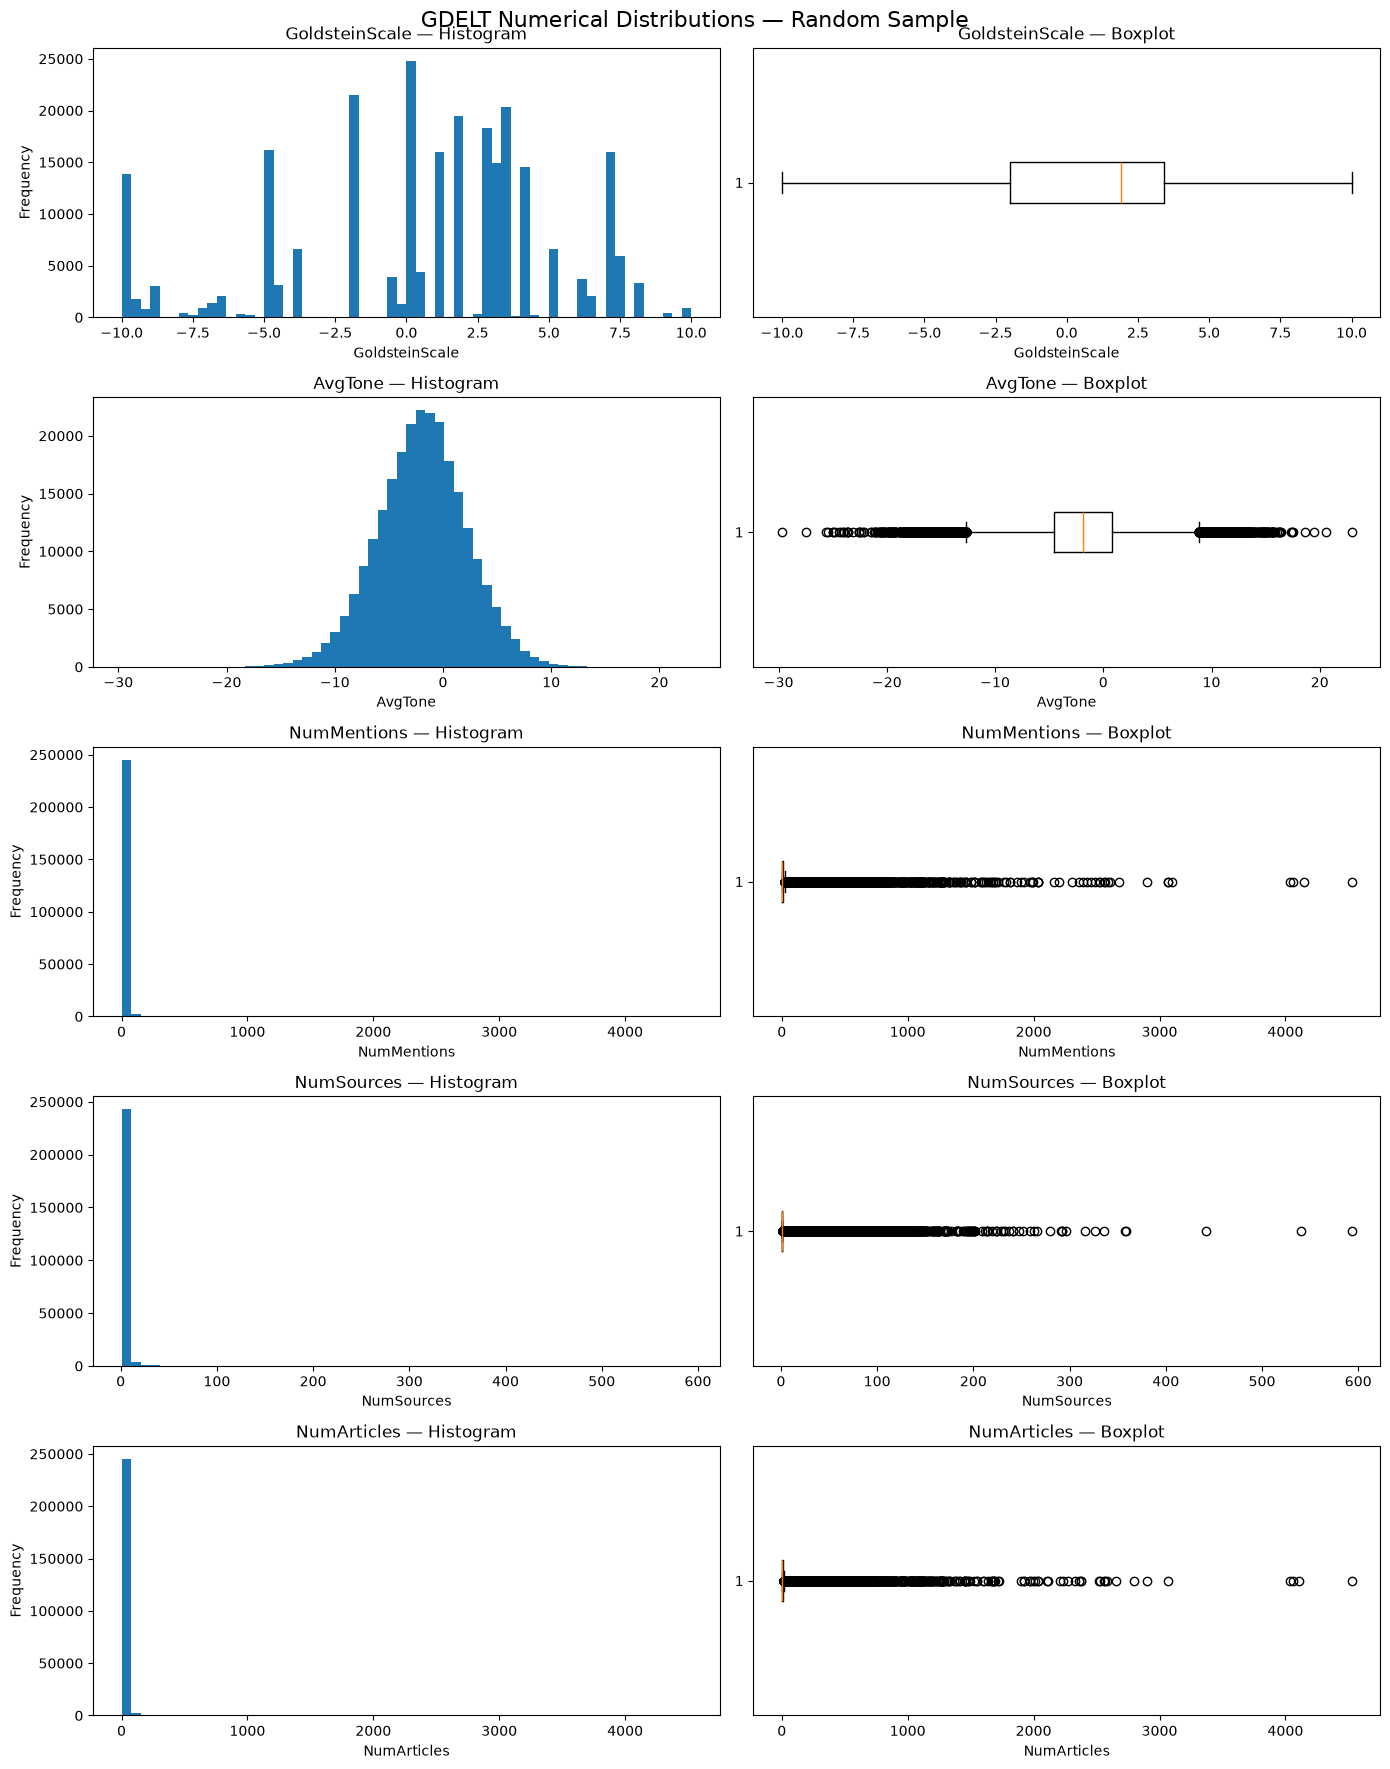

In [30]:

# Plot numerical distributions using the sample

fig, axes = plt.subplots(
    len(numeric_cols), 2,
    figsize=(14, 18)
)

for i, col in enumerate(numeric_cols):
    values = numeric_sample[col].dropna()

    # Histogram
    axes[i, 0].hist(
        values,
        bins=60
    )
    axes[i, 0].set_title(f"{col} — Histogram")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frequency")

    # Boxplot
    axes[i, 1].boxplot(
        values.to_numpy(),
        orientation="horizontal"
    )
    axes[i, 1].set_title(f"{col} — Boxplot")
    axes[i, 1].set_xlabel(col)

fig.suptitle(
    "GDELT Numerical Distributions — Random Sample",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    PROFILE_DIR / "numeric_distributions.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()



### Systematic Missingness — Event Categories and Time

This investigation examines whether missing actor-country and geographic information differs systematically across CAMEO event categories and daily reporting periods.

The objective is to determine whether missingness may introduce bias into country-level geopolitical indicators.

Missingness is measured across the entire dataset using chunked processing, rather than a sample. No missing values are imputed or removed during this investigation.


In [31]:

# Analyze missingness by event category across the full dataset

target_cols = [
    "Actor1CountryCode",
    "Actor2CountryCode",
    "ActionGeo_CountryCode"
]

use_cols = ["EventRootCode"] + target_cols

category_summary = None

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=use_cols,
        dtype="string",
        chunksize=100_000
    ),
    start=1
):
    temp = pd.DataFrame({
        "EventRootCode": chunk["EventRootCode"],
        "Total": 1,
        "Actor1_Missing": chunk["Actor1CountryCode"].isna().astype(int),
        "Actor2_Missing": chunk["Actor2CountryCode"].isna().astype(int),
        "ActionGeo_Missing": chunk["ActionGeo_CountryCode"].isna().astype(int)
    })

    grouped = temp.groupby("EventRootCode", dropna=False).sum()

    if category_summary is None:
        category_summary = grouped
    else:
        category_summary = category_summary.add(
            grouped, fill_value=0
        )

    if i % 20 == 0:
        print(f"Processed {i * 100_000:,} rows")

# Calculate missing percentages
missing_by_category = category_summary.copy()

for col in ["Actor1", "Actor2", "ActionGeo"]:
    missing_by_category[f"{col}_Missing_Pct"] = (
        missing_by_category[f"{col}_Missing"] /
        missing_by_category["Total"] * 100
    ).round(2)

missing_by_category = missing_by_category.sort_values(
    "Total", ascending=False
)

display(missing_by_category)

missing_by_category.to_csv(
    PROFILE_DIR / "missingness_by_event_category.csv"
)


Processed 2,000,000 rows
Processed 4,000,000 rows
Processed 6,000,000 rows
Processed 8,000,000 rows
Processed 10,000,000 rows
Processed 12,000,000 rows
Processed 14,000,000 rows
Processed 16,000,000 rows
Processed 18,000,000 rows
Processed 20,000,000 rows


,Total,Actor1_Missing,Actor2_Missing,ActionGeo_Missing,Actor1_Missing_Pct,Actor2_Missing_Pct,ActionGeo_Missing_Pct
EventRootCode,,,,,,,
04,5103696.0,2163402.0,2186106.0,101277.0,42.39,42.83,1.98
01,2856569.0,1194285.0,1817051.0,71316.0,41.81,63.61,2.50
05,1799597.0,735708.0,940308.0,40219.0,40.88,52.25,2.23
02,1450320.0,654321.0,906880.0,39917.0,45.12,62.53,2.75
03,1359217.0,584008.0,685134.0,39629.0,42.97,50.41,2.92
11,1294549.0,581386.0,734208.0,36363.0,44.91,56.72,2.81
19,1171487.0,502387.0,626547.0,34630.0,42.88,53.48,2.96
17,1031142.0,470861.0,582382.0,33797.0,45.66,56.48,3.28
08,746460.0,315375.0,435197.0,25353.0,42.25,58.30,3.40


heat map of Systematic Missingness

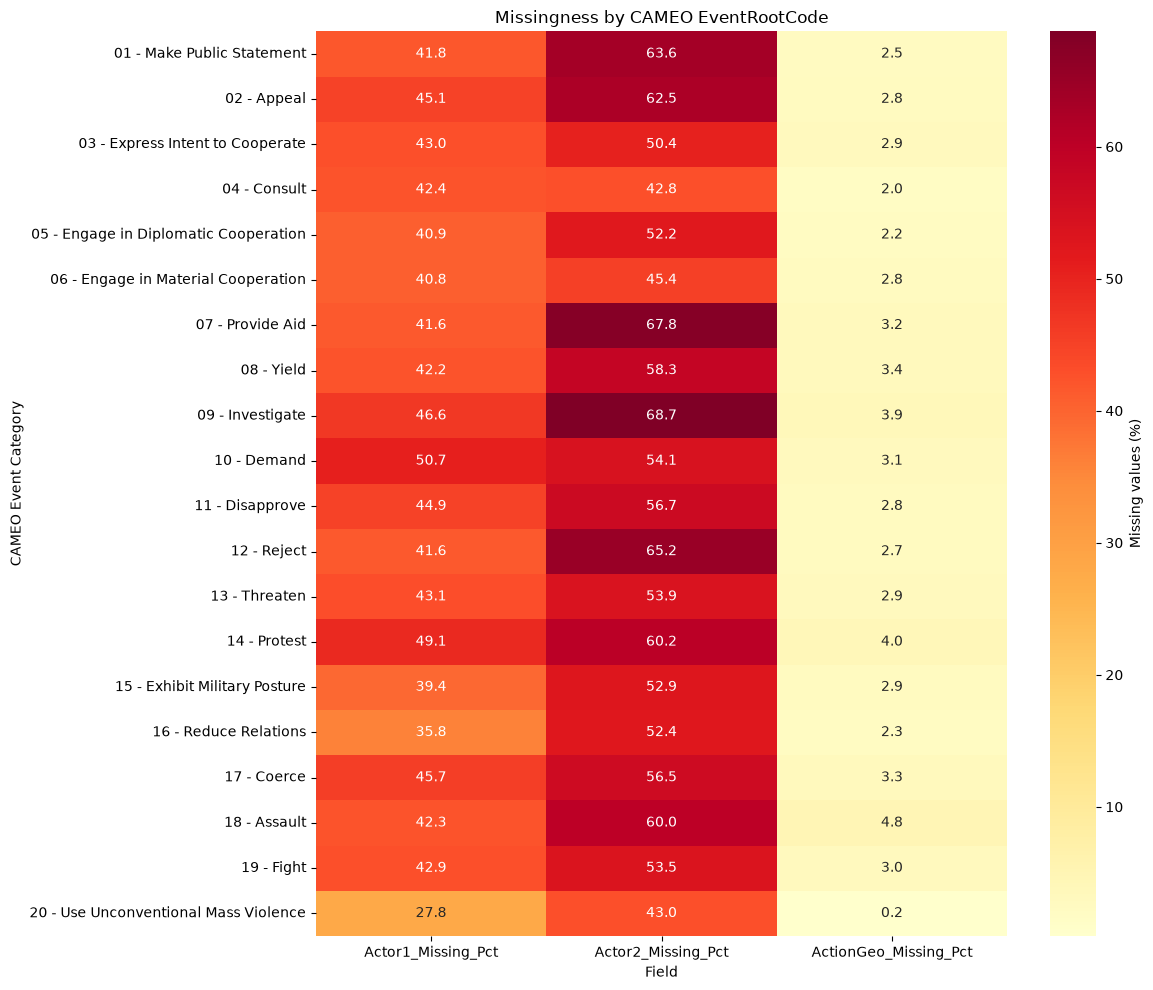

In [33]:
# CAMEO EventRootCode descriptions
cameo_root_labels = {
    "01": "Make Public Statement",
    "02": "Appeal",
    "03": "Express Intent to Cooperate",
    "04": "Consult",
    "05": "Engage in Diplomatic Cooperation",
    "06": "Engage in Material Cooperation",
    "07": "Provide Aid",
    "08": "Yield",
    "09": "Investigate",
    "10": "Demand",
    "11": "Disapprove",
    "12": "Reject",
    "13": "Threaten",
    "14": "Protest",
    "15": "Exhibit Military Posture",
    "16": "Reduce Relations",
    "17": "Coerce",
    "18": "Assault",
    "19": "Fight",
    "20": "Use Unconventional Mass Violence"
}

# Select missingness columns
heatmap_data = missing_by_category[
    [
        "Actor1_Missing_Pct",
        "Actor2_Missing_Pct",
        "ActionGeo_Missing_Pct"
    ]
].copy()

# Only standard CAMEO root categories
standard_codes = [f"{i:02d}" for i in range(1, 21)]

heatmap_data = heatmap_data.loc[
    heatmap_data.index.isin(standard_codes)
].sort_index()

# Create descriptive Y-axis labels
y_labels = [
    f"{code} - {cameo_root_labels[code]}"
    for code in heatmap_data.index
]

# Plot heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    yticklabels=y_labels,
    cbar_kws={"label": "Missing values (%)"}
)

plt.title("Missingness by CAMEO EventRootCode")
plt.xlabel("Field")
plt.ylabel("CAMEO Event Category")

plt.yticks(rotation=0)
plt.tight_layout()

# Save figure
plt.savefig(
    PROFILE_DIR / "missingness_by_event_category.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

Geographic Missingness Over Time

This investigation examines whether the availability of geographic information changes across daily GDELT archives.

A time-series plot is used to identify sudden increases in missing geographic or actor-country information that could indicate changes in news coverage, event extraction, or processing quality.

In [34]:

# Calculate daily missingness percentages using DATEADDED

daily_summary = None

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=["DATEADDED"] + target_cols,
        dtype="string",
        chunksize=100_000
    ),
    start=1
):
    temp = pd.DataFrame({
        "Date": chunk["DATEADDED"].str[:8],
        "Total": 1,
        "Actor1_Missing": chunk["Actor1CountryCode"].isna().astype(int),
        "Actor2_Missing": chunk["Actor2CountryCode"].isna().astype(int),
        "ActionGeo_Missing": chunk["ActionGeo_CountryCode"].isna().astype(int)
    })

    grouped = temp.groupby("Date").sum()

    if daily_summary is None:
        daily_summary = grouped
    else:
        daily_summary = daily_summary.add(
            grouped, fill_value=0
        )

    if i % 20 == 0:
        print(f"Processed {i * 100_000:,} rows")

daily_missingness = daily_summary.copy()

for col in ["Actor1", "Actor2", "ActionGeo"]:
    daily_missingness[f"{col}_Missing_Pct"] = (
        daily_missingness[f"{col}_Missing"] /
        daily_missingness["Total"] * 100
    ).round(2)

daily_missingness.index = pd.to_datetime(
    daily_missingness.index,
    format="%Y%m%d"
)

daily_missingness = daily_missingness.sort_index()

display(daily_missingness.head())

daily_missingness.to_csv(
    PROFILE_DIR / "daily_missingness.csv"
)


Processed 2,000,000 rows
Processed 4,000,000 rows
Processed 6,000,000 rows
Processed 8,000,000 rows
Processed 10,000,000 rows
Processed 12,000,000 rows
Processed 14,000,000 rows
Processed 16,000,000 rows
Processed 18,000,000 rows
Processed 20,000,000 rows


,Total,Actor1_Missing,Actor2_Missing,ActionGeo_Missing,Actor1_Missing_Pct,Actor2_Missing_Pct,ActionGeo_Missing_Pct
Date,,,,,,,
2025-01-01,71207.0,31366.0,40497.0,2268.0,44.05,56.87,3.19
2025-01-02,91632.0,40523.0,52051.0,2862.0,44.22,56.80,3.12
2025-01-03,106495.0,47619.0,60642.0,3255.0,44.71,56.94,3.06
2025-01-04,74608.0,34204.0,42556.0,2637.0,45.84,57.04,3.53
2025-01-05,64742.0,27970.0,35098.0,1983.0,43.20,54.21,3.06


Daily missingness visulatization

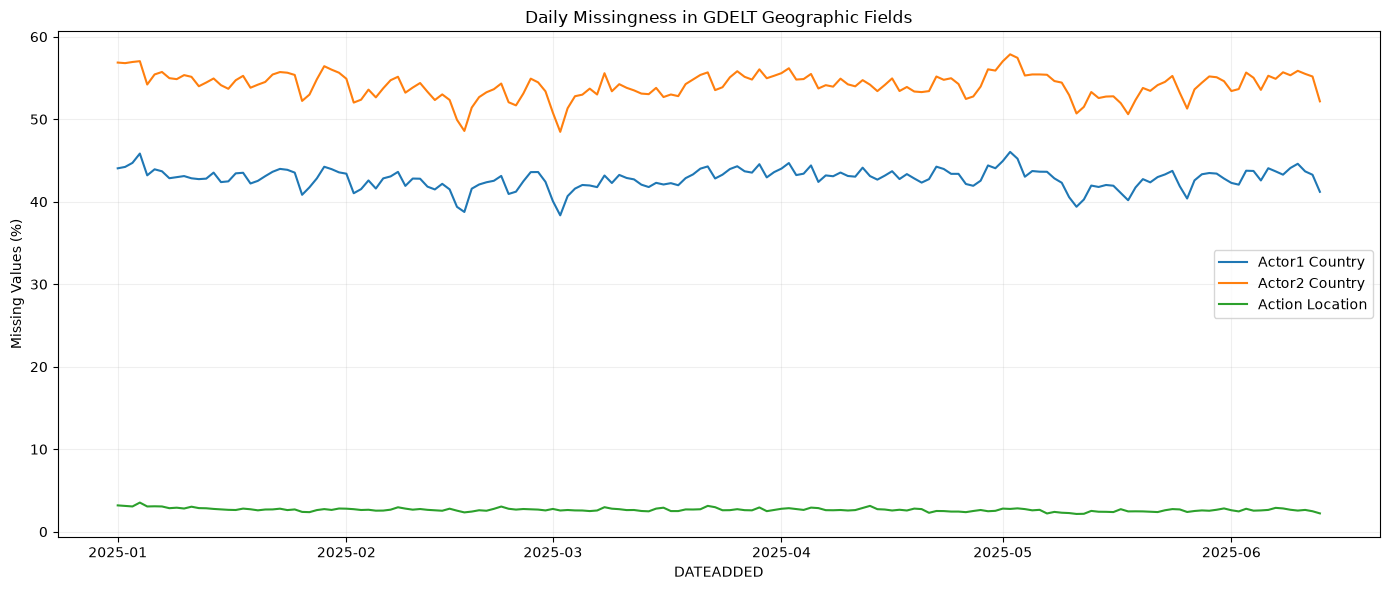

In [35]:

plt.figure(figsize=(14, 6))

for col, label in [
    ("Actor1_Missing_Pct", "Actor1 Country"),
    ("Actor2_Missing_Pct", "Actor2 Country"),
    ("ActionGeo_Missing_Pct", "Action Location")
]:
    plt.plot(
        daily_missingness.index,
        daily_missingness[col],
        label=label,
        linewidth=1.5
    )

plt.title("Daily Missingness in GDELT Geographic Fields")
plt.xlabel("DATEADDED")
plt.ylabel("Missing Values (%)")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    PROFILE_DIR / "daily_geographic_missingness.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
